# 02 · Exploración de cinco años: clasificación ABC y XYZ global

Flujo: (1) cargar y revisar las fuentes, (2) calcular las métricas por artículo sobre los cinco años, (3) clasificar ABC y XYZ, (4) cruzar ABC × XYZ y (5) graficar. Cada cálculo se hace a la vista y su resultado se muestra en el notebook. No se congela nada.

In [1]:
import os
import sys
from pathlib import Path

# Raíz del código: el notebook corre desde notebooks/. PROJECT_ROOT permite apuntar a otra carpeta
# de datos (por ejemplo, una copia sintética para validar el flujo).
CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_ROOT))
os.chdir(os.environ.get("PROJECT_ROOT", CODE_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

from src.config import all_years, load_validated_config
from src.data import load_calendar, load_interim
from src.segmentation import (
    build_matrix,
    classify_abc,
    classify_xyz,
    compute_cv,
    compute_usage_spend,
    describe_items,
    find_cv_cuts,
)

# Si es True, la figura de la sección 5 se guarda en reports/figures/.
SAVE_FIGURES = False

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
%matplotlib inline

cfg = load_validated_config()
seg = cfg["segmentation"]
print("versión de la config:", cfg["version"])
print("segmentación:", seg)

versión de la config: v1
segmentación: {'usage_period': 'computation_set', 'abc_cuts': [0.8, 0.95], 'xyz_thresholds': [10.0, 25.0], 'cv_aggregation': 'block28', 'cv_min_blocks': 2}


## 1 · Fuentes de datos

Vista previa de los archivos crudos y de los arreglos intermedios que alimentan los cálculos.

In [2]:
raw_dir = Path(cfg["data"]["raw_dir"])
last_day = cfg["data"]["last_day"]

# Calendario: un registro por día (d_1 … d_n) con su semana wm_yr_wk.
calendar = load_calendar(cfg)
print(f"calendar.csv: {calendar.shape[0]} días, de {calendar['date'].min()} a {calendar['date'].max()}")
display(calendar.head())

calendar.csv: 1969 días, de 2011-01-29 a 2016-06-19


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [3]:
# Ventas crudas (solo 5 filas y las primeras columnas de días): una fila por serie tienda-artículo.
sales_head = pd.read_csv(raw_dir / cfg["data"]["sales_file"], nrows=5)
print(f"{cfg['data']['sales_file']}: {sales_head.shape[1]} columnas en la vista previa")
display(sales_head.iloc[:, :12])

# Precios crudos (solo 5 filas): precio de venta por tienda, artículo y semana.
prices_head = pd.read_csv(raw_dir / "sell_prices.csv", nrows=5)
display(prices_head)

sales_train_evaluation.csv: 1947 columnas en la vista previa


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_5,d_6
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [4]:
# Intermedios por artículo (unidades y gasto = Σ unidades × precio por tienda-día), días 1..last_day.
# NaN = día sin dato (prelanzamiento o enmascarado).
source_data_artifact = load_interim(cfg, last_day)
item_ids = source_data_artifact["item_ids"]
print(f"artículos: {len(item_ids)} · días: {source_data_artifact['item_units'].shape[1]}")

day_cols = [f"d_{d}" for d in range(1, 9)]
display(pd.DataFrame(source_data_artifact["item_units"][:5, :8], index=item_ids[:5], columns=day_cols).rename_axis("unidades"))
display(pd.DataFrame(source_data_artifact["item_spend"][:5, :8], index=item_ids[:5], columns=day_cols).rename_axis("gasto"))
display(pd.DataFrame({"item_id": item_ids, "item_launch_d": source_data_artifact["item_launch_d"]}).head())

artículos: 3049 · días: 1941


,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8
unidades,,,,,,,,
FOODS_1_001,6.00,6.00,4.00,6.00,7.00,18.00,10.00,4.00
FOODS_1_002,4.00,5.00,7.00,4.00,3.00,4.00,1.00,7.00
FOODS_1_003,14.00,8.00,3.00,6.00,3.00,8.00,13.00,10.00
FOODS_1_004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOODS_1_005,34.00,32.00,13.00,20.00,10.00,21.00,18.00,20.00


,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8
gasto,,,,,,,,
FOODS_1_001,12.00,12.00,8.00,12.00,14.00,36.00,20.00,8.00
FOODS_1_002,31.92,39.40,55.16,31.52,23.64,31.92,7.88,55.16
FOODS_1_003,40.32,23.04,8.64,17.28,8.64,23.04,37.44,28.80
FOODS_1_004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FOODS_1_005,100.86,94.38,38.52,59.10,29.40,63.24,53.22,59.40


,item_id,item_launch_d
0,FOODS_1_001,1.00
1,FOODS_1_002,1.00
2,FOODS_1_003,1.00
3,FOODS_1_004,400.00
4,FOODS_1_005,1.00


In [5]:
# Ventana de los cinco años (los días anteriores a Y1 son historia previa y no se usan aquí).
years = all_years(cfg)
years_table = pd.DataFrame(years, index=["start_d", "end_d"]).T
years_table["days"] = years_table["end_d"] - years_table["start_d"] + 1
display(years_table)

start_d, end_d = years["Y1"][0], years["Y5"][1]
print(f"ventana global: d_{start_d} a d_{end_d} ({end_d - start_d + 1} días)")

,start_d,end_d,days
Y1,122,485,364
Y2,486,849,364
Y3,850,1213,364
Y4,1214,1577,364
Y5,1578,1941,364


ventana global: d_122 a d_1941 (1820 días)


## 2 · Métricas globales (los cinco años)

- **Uso** y **gasto**: suma de unidades y de Σ unidades × precio en la ventana; un artículo es *activo* si tiene al menos un día con dato.
- **CV**: desviación estándar poblacional / media × 100 sobre bloques completos de 28 días (`cv_aggregation = block28`); es indefinido con menos de `cv_min_blocks` bloques o media 0.
- **Descripción diaria**: media, mediana y proporción de ceros sobre días activos.

In [6]:
# Uso y gasto por artículo.
usage_spend = compute_usage_spend(source_data_artifact["item_units"], source_data_artifact["item_spend"], start_d, end_d)
usage_spend.insert(0, "item_id", item_ids)
display(usage_spend.head())

# CV por artículo.
cv_df = compute_cv(
    source_data_artifact["item_units"], start_d, end_d, seg["cv_aggregation"], seg["cv_min_blocks"], source_data_artifact["week_of_day"]
)
display(cv_df.head())

# Media, mediana y proporción de ceros por día.
daily = describe_items(source_data_artifact, start_d, end_d)
display(daily.head())

,item_id,usage,spend,active
0,FOODS_1_001,"11,145.00","24,087.18",True
1,FOODS_1_002,"7,008.00","63,094.62",True
2,FOODS_1_003,"12,445.00","36,732.64",True
3,FOODS_1_004,"132,251.00","241,427.22",True
4,FOODS_1_005,"21,098.00","71,388.14",True


,cv,n_blocks
0,42.49,65
1,12.95,65
2,25.72,65
3,43.64,55
4,65.06,65


,item_id,active_days,zero_share,mean_daily_units,median_daily_units,total_units
0,FOODS_1_001,1820,0.10,6.12,5.00,"11,145.00"
1,FOODS_1_002,1820,0.04,3.85,4.00,"7,008.00"
2,FOODS_1_003,1820,0.02,6.84,6.00,"12,445.00"
3,FOODS_1_004,1542,0.10,85.77,84.00,"132,251.00"
4,FOODS_1_005,1820,0.24,11.59,11.00,"21,098.00"


In [7]:
usage_spend

,item_id,usage,spend,active
0,FOODS_1_001,"11,145.00","24,087.18",True
1,FOODS_1_002,"7,008.00","63,094.62",True
2,FOODS_1_003,"12,445.00","36,732.64",True
3,FOODS_1_004,"132,251.00","241,427.22",True
4,FOODS_1_005,"21,098.00","71,388.14",True
...,...,...,...,...
3044,HOUSEHOLD_2_512,"10,992.00","43,634.34",True
3045,HOUSEHOLD_2_513,"8,012.00","22,273.36",True
3046,HOUSEHOLD_2_514,"3,104.00","58,592.63",True
3047,HOUSEHOLD_2_515,"1,153.00","2,270.42",True


In [8]:
# Una sola tabla de métricas por artículo.
metrics = (
    usage_spend.rename(columns={"usage": "usage_units"})
    .join(cv_df)
    .merge(daily.drop(columns="total_units"), on="item_id")
)
display(metrics.head())

# Resumen global: lo que se agrega y lo que queda sin cálculo.
active = metrics[metrics["active"]]
summary = pd.Series(
    {
        "artículos": len(metrics),
        "activos en la ventana": len(active),
        "inactivos": int((~metrics["active"]).sum()),
        "activos con CV indefinido": int(active["cv"].isna().sum()),
        "unidades totales": metrics["usage_units"].sum(),
        "gasto total": metrics["spend"].sum(),
        "CV mediano (%)": active["cv"].median(),
    },
    name="valor",
)
display(summary.to_frame())
display(metrics[["usage_units", "spend", "cv", "n_blocks", "mean_daily_units", "median_daily_units", "zero_share"]].describe())

,item_id,usage_units,spend,active,cv,n_blocks,active_days,zero_share,mean_daily_units,median_daily_units
0,FOODS_1_001,"11,145.00","24,087.18",True,42.49,65,1820,0.10,6.12,5.00
1,FOODS_1_002,"7,008.00","63,094.62",True,12.95,65,1820,0.04,3.85,4.00
2,FOODS_1_003,"12,445.00","36,732.64",True,25.72,65,1820,0.02,6.84,6.00
3,FOODS_1_004,"132,251.00","241,427.22",True,43.64,55,1542,0.10,85.77,84.00
4,FOODS_1_005,"21,098.00","71,388.14",True,65.06,65,1820,0.24,11.59,11.00


,valor
artículos,"3,049.00"
activos en la ventana,"3,049.00"
inactivos,0.00
activos con CV indefinido,0.00
unidades totales,"63,933,886.00"
gasto total,"183,470,201.68"
CV mediano (%),37.16


,usage_units,spend,cv,n_blocks,mean_daily_units,median_daily_units,zero_share
count,"3,049.00","3,049.00","3,049.00","3,049.00","3,049.00","3,049.00","3,049.00"
mean,"20,968.80","60,173.89",41.80,54.80,13.03,12.11,0.15
std,"42,891.36","91,194.62",22.02,14.20,24.46,23.79,0.14
min,593.00,457.93,8.49,14.00,0.35,0.00,0.00
25%,"4,320.00","17,731.57",25.61,45.00,3.22,3.00,0.03
50%,"9,369.00","34,252.08",37.16,65.00,6.26,6.00,0.10
75%,"20,748.00","65,949.90",53.91,65.00,13.03,12.00,0.22
max,"1,008,855.00","1,444,850.11",192.52,65.00,554.32,556.00,0.78


## 3 · Matriz de clasificación por artículo

- **ABC**: se ordena por gasto descendente y se mira el % acumulado *antes* de sumar el artículo; es A si es menor que el primer corte, B si es menor que el segundo y C en otro caso.
- **XYZ**: X si CV < umbral X, Y si CV < umbral Z y Z en otro caso.

In [9]:
# ABC: solo artículos activos, ordenados por gasto (empates por item_id).
abc = classify_abc(active["item_id"], active["spend"].to_numpy(), seg["abc_cuts"])
display(abc.head())
display(abc.groupby("abc_class").agg(items=("item_id", "size"), spend=("spend", "sum")).assign(
    spend_pct=lambda t: t["spend"] / t["spend"].sum() * 100))

,item_id,spend,cum_spend,cum_pct_before,abc_class
0,FOODS_3_120,"1,444,850.11","1,444,850.11",0.00,A
1,FOODS_3_586,"1,395,728.81","2,840,578.91",0.01,A
2,FOODS_3_090,"1,366,337.80","4,206,916.71",0.02,A
3,FOODS_3_202,"1,212,799.69","5,419,716.40",0.02,A
4,FOODS_3_587,"893,838.15","6,313,554.55",0.03,A


,items,spend,spend_pct
abc_class,,,
A,1274,"146,803,540.23",80.01
B,928,"27,506,032.44",14.99
C,847,"9,160,629.00",4.99


Pareto con doble eje y sensibilidad de los cortes ABC

Barras: gasto anual promedio por artículo (gasto de los cinco años / 5), en el eje principal. Línea: gasto acumulado porcentual, en el eje secundario. Las barras se colorean con los cortes configurados.

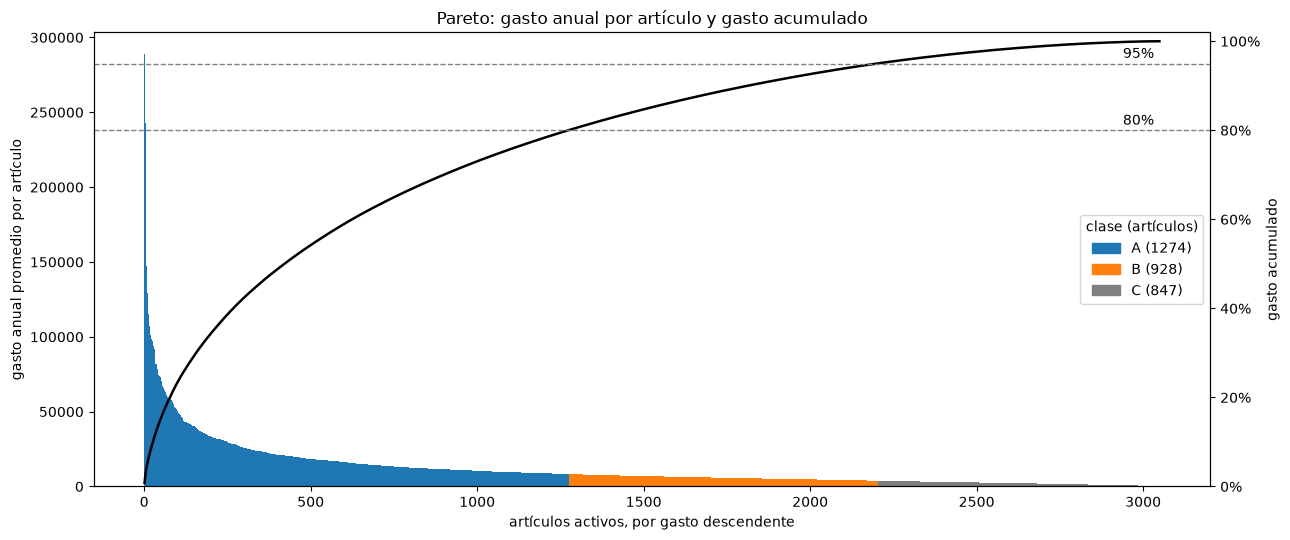

In [10]:
n_years = len(years)
colors = {"A": "#1f77b4", "B": "#ff7f0e", "C": "#7f7f7f"}
# abc ya trae solo los artículos activos, ordenados por gasto, con cum_spend y abc_class.
ranked = abc.copy()
rank = np.arange(1, len(ranked) + 1)
annual_spend = ranked["spend"] / n_years
cum_pct = ranked["cum_spend"] / ranked["spend"].sum()

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(rank, annual_spend, width=1.0, color=ranked["abc_class"].map(colors), linewidth=0)
ax.set(title="Pareto: gasto anual por artículo y gasto acumulado", xlabel="artículos activos, por gasto descendente",
       ylabel="gasto anual promedio por artículo")
ax.margins(x=0)

ax2 = ax.twinx()
ax2.plot(rank, cum_pct, color="black", linewidth=1.8)
for cut in seg["abc_cuts"]:
    ax2.axhline(cut, color="grey", linestyle="--", linewidth=1)
    ax2.annotate(f"{cut:.0%}", (rank[-1], cut), xytext=(-4, 4), textcoords="offset points", ha="right")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.set(ylabel="gasto acumulado", ylim=(0, 1.02))

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, [f"{k} ({(ranked['abc_class'] == k).sum()})" for k in colors], title="clase (artículos)", loc="center right")
fig.tight_layout()
if SAVE_FIGURES:
    out = Path("reports/figures")
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "eda_five_years_pareto.png", dpi=150, bbox_inches="tight")
    print("figura guardada en", out / "eda_five_years_pareto.png")
plt.show()

### Escenarios de corte

Se repite `classify_abc` con distintos cortes de gasto acumulado (A, B). Por cada escenario: recuento de artículos, % de los artículos (unidades de inventario, SKU) y % del gasto de cada clase.

In [11]:
a_cuts = [0.50, 0.60, 0.70, 0.80, 0.90]
b_cuts = [0.90, 0.95, 0.98]
total_items = len(ranked)

rows = []
for a in a_cuts:
    for b in b_cuts:
        if a >= b:
            continue
        r = classify_abc(ranked["item_id"], ranked["spend"].to_numpy(), [a, b])
        by = r.groupby("abc_class").agg(items=("item_id", "size"), spend=("spend", "sum"))
        by = by.reindex(["A", "B", "C"], fill_value=0)
        row = {"corte_A": a, "corte_B": b}
        for cls in ("A", "B", "C"):
            row[f"{cls}_items"] = int(by.loc[cls, "items"])
            row[f"{cls}_%items"] = by.loc[cls, "items"] / total_items * 100
            row[f"{cls}_%gasto"] = by.loc[cls, "spend"] / by["spend"].sum() * 100
        rows.append(row)
scenarios = pd.DataFrame(rows)
scenarios["escenario"] = [f"A≤{a:.0%} · B≤{b:.0%}" for a, b in zip(scenarios["corte_A"], scenarios["corte_B"])]
assert (scenarios[["A_items", "B_items", "C_items"]].sum(axis=1) == total_items).all()
display(scenarios.set_index("escenario").round(2))

,corte_A,corte_B,A_items,A_%items,A_%gasto,B_items,B_%items,B_%gasto,C_items,C_%items,C_%gasto
escenario,,,,,,,,,,,
A≤50% · B≤90%,0.50,0.90,421,13.81,50.01,1391,45.62,39.99,1237,40.57,10.00
A≤50% · B≤95%,0.50,0.95,421,13.81,50.01,1781,58.41,45.00,847,27.78,4.99
A≤50% · B≤98%,0.50,0.98,421,13.81,50.01,2127,69.76,47.99,501,16.43,2.00
A≤60% · B≤90%,0.60,0.90,625,20.50,60.04,1187,38.93,29.96,1237,40.57,10.00
A≤60% · B≤95%,0.60,0.95,625,20.50,60.04,1577,51.72,34.97,847,27.78,4.99
A≤60% · B≤98%,0.60,0.98,625,20.50,60.04,1923,63.07,37.96,501,16.43,2.00
A≤70% · B≤90%,0.70,0.90,900,29.52,70.03,912,29.91,19.98,1237,40.57,10.00
A≤70% · B≤95%,0.70,0.95,900,29.52,70.03,1302,42.70,24.98,847,27.78,4.99
A≤70% · B≤98%,0.70,0.98,900,29.52,70.03,1648,54.05,27.97,501,16.43,2.00


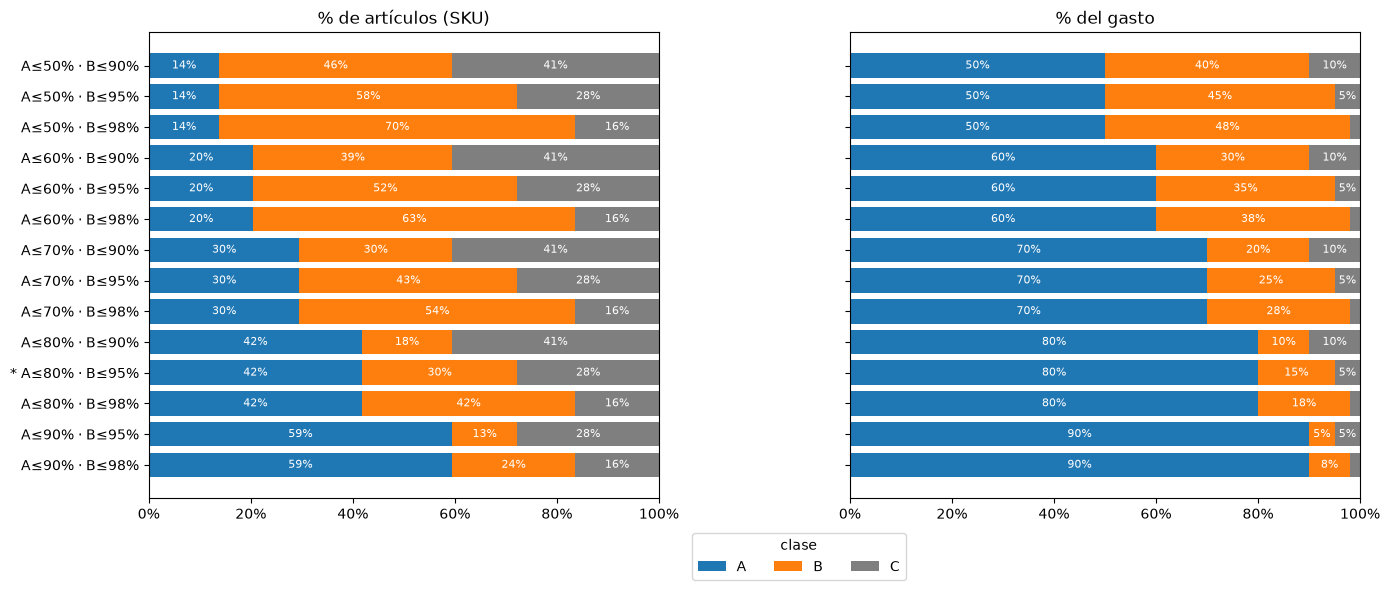

In [12]:
# Reparto de artículos y de gasto por escenario (el escenario configurado va marcado con *).
labels = [("* " if [a, b] == list(seg["abc_cuts"]) else "") + e
          for a, b, e in zip(scenarios["corte_A"], scenarios["corte_B"], scenarios["escenario"])]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, kind, title in zip(axes, ("%items", "%gasto"), ("% de artículos (SKU)", "% del gasto")):
    left = np.zeros(len(scenarios))
    for cls, color in colors.items():
        vals = scenarios[f"{cls}_{kind}"].to_numpy()
        ax.barh(labels, vals, left=left, color=color, label=cls)
        for y, (l, v) in enumerate(zip(left, vals)):
            if v >= 4:
                ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8)
        left += vals
    ax.set(title=title, xlim=(0, 100))
    ax.xaxis.set_major_formatter(PercentFormatter(100))
axes[0].invert_yaxis()
axes[1].legend(title="clase", loc="upper center", bbox_to_anchor=(-0.1, -0.06), ncol=3)
fig.tight_layout()
plt.show()

In [13]:
# Cortes seleccionados mediante itertacion
CUT_A = 0.6
CUT_B = 0.9

# ABC: solo artículos activos, ordenados por gasto (empates por item_id).
abc = classify_abc(active["item_id"], active["spend"].to_numpy(), [CUT_A, CUT_B])
display(abc.head())
display(abc.groupby("abc_class").agg(items=("item_id", "size"), spend=("spend", "sum")).assign(
    spend_pct=lambda t: t["spend"] / t["spend"].sum() * 100))

,item_id,spend,cum_spend,cum_pct_before,abc_class
0,FOODS_3_120,"1,444,850.11","1,444,850.11",0.00,A
1,FOODS_3_586,"1,395,728.81","2,840,578.91",0.01,A
2,FOODS_3_090,"1,366,337.80","4,206,916.71",0.02,A
3,FOODS_3_202,"1,212,799.69","5,419,716.40",0.02,A
4,FOODS_3_587,"893,838.15","6,313,554.55",0.03,A


,items,spend,spend_pct
abc_class,,,
A,625,"110,154,355.39",60.04
B,1187,"54,975,936.54",29.96
C,1237,"18,339,909.75",10.00


figura guardada en reports/figures/eda_five_years_pareto.png


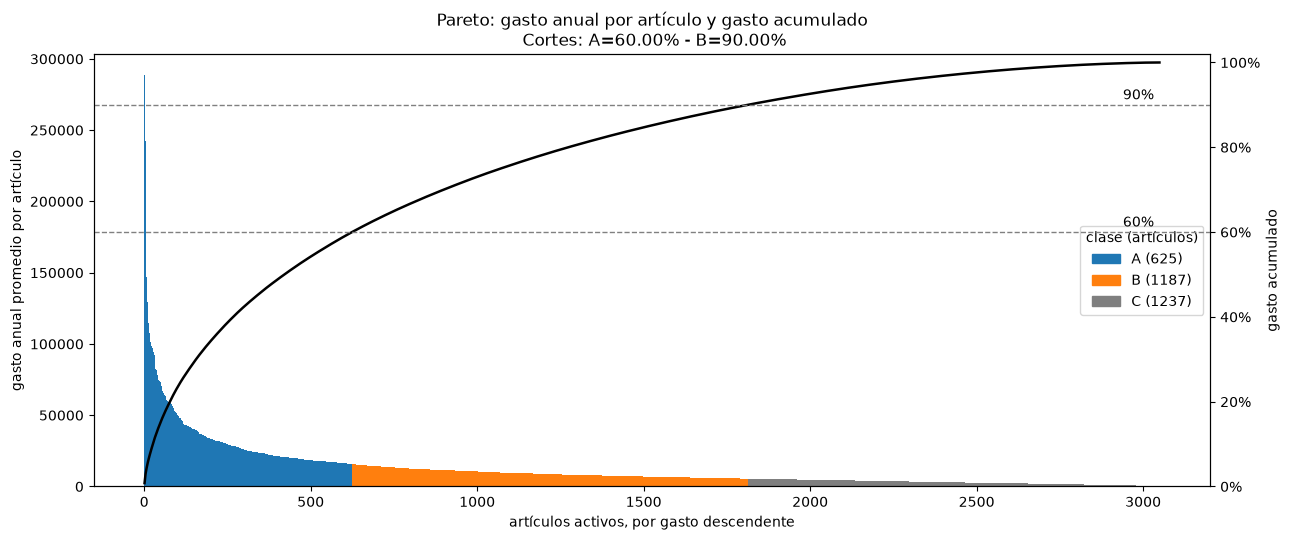

In [14]:
n_years = len(years)
colors = {"A": "#1f77b4", "B": "#ff7f0e", "C": "#7f7f7f"}
# abc ya trae solo los artículos activos, ordenados por gasto, con cum_spend y abc_class.
ranked = abc.copy()
rank = np.arange(1, len(ranked) + 1)
annual_spend = ranked["spend"] / n_years
cum_pct = ranked["cum_spend"] / ranked["spend"].sum()

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(rank, annual_spend, width=1.0, color=ranked["abc_class"].map(colors), linewidth=0)
ax.set(title=f"Pareto: gasto anual por artículo y gasto acumulado\n Cortes: A={CUT_A:.2%} - B={CUT_B:.2%}", xlabel="artículos activos, por gasto descendente",
       ylabel="gasto anual promedio por artículo")
ax.margins(x=0)

ax2 = ax.twinx()
ax2.plot(rank, cum_pct, color="black", linewidth=1.8)
for cut in [CUT_A, CUT_B]:
    ax2.axhline(cut, color="grey", linestyle="--", linewidth=1)
    ax2.annotate(f"{cut:.0%}", (rank[-1], cut), xytext=(-4, 4), textcoords="offset points", ha="right")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.set(ylabel="gasto acumulado", ylim=(0, 1.02))

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, [f"{k} ({(ranked['abc_class'] == k).sum()})" for k in colors], title="clase (artículos)", loc="center right")
fig.tight_layout()

SAVE_FIGURES = True
if SAVE_FIGURES:
    out = Path("reports/figures")
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "eda_five_years_pareto.png", dpi=150, bbox_inches="tight")
    print("figura guardada en", out / "eda_five_years_pareto.png")
plt.show()

## 4 · Cortes XYZ a partir de la distribución del CV

En lugar de los umbrales fijos 10% y 25%, se buscan los cortes del CV con una búsqueda de cambios de nivel al estilo `ruptures`: los artículos se ordenan por CV y el gasto en ese orden es la señal. Compiten solo las particiones que cumplen (1) un mínimo de artículos por segmento y (2) gasto medio por artículo descendente de X a Z. Entre ellas gana la que más separa los niveles de gasto (costo L2).

In [15]:
# XYZ: sobre el CV de los artículos activos.
xyz = classify_xyz(active["cv"], seg["xyz_thresholds"])
display(xyz.value_counts(dropna=False).rename("items").to_frame())

,items
Z,2337
Y,701
X,11


In [16]:
matrix = (
    metrics[["item_id", "active", "usage_units", "spend", "cv", "n_blocks"]]
    .merge(abc[["item_id", "cum_spend", "cum_pct_before", "abc_class"]], on="item_id", how="left")
    .merge(
        pd.DataFrame({"item_id": active["item_id"].to_numpy(), "xyz_class": xyz.to_numpy()}),
        on="item_id",
        how="left",
    )
    .sort_values(["active", "spend", "item_id"], ascending=[False, False, True])
    .reset_index(drop=True)
)

In [17]:
# Parámetros de la búsqueda.
N_CUTS = 2          # número de cortes: N_CUTS + 1 segmentos (con 2: X, Y, Z)
MIN_SHARE = 0.20    # mínimo de artículos (unidades de inventario) por segmento
RESOLUTION = 100    # posiciones candidatas de corte repartidas en la distribución

cv_items = matrix.loc[matrix["cv"].notna(), ["item_id", "cv", "spend"]]
print(f"artículos con CV definido: {len(cv_items)}")
display(cv_items["cv"].describe().to_frame())

artículos con CV definido: 3049


,cv
count,"3,049.00"
mean,41.80
std,22.02
min,8.49
25%,25.61
50%,37.16
75%,53.91
max,192.52


### Distribución del CV

Escala nativa y escala logarítmica, con los umbrales actuales (10% y 25%) como referencia.

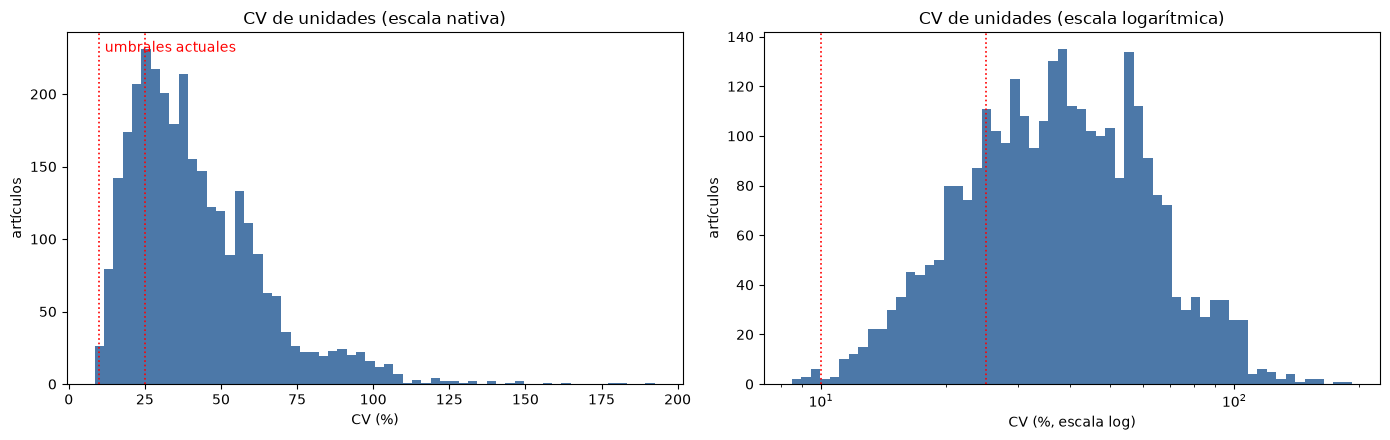

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cv_vals = cv_items["cv"]

axes[0].hist(cv_vals, bins=60, color="#4c78a8")
axes[0].set(title="CV de unidades (escala nativa)", xlabel="CV (%)", ylabel="artículos")

axes[1].hist(cv_vals, bins=np.logspace(np.log10(cv_vals.min()), np.log10(cv_vals.max()), 60), color="#4c78a8")
axes[1].set_xscale("log")
axes[1].set(title="CV de unidades (escala logarítmica)", xlabel="CV (%, escala log)", ylabel="artículos")

for ax in axes:
    for thr in seg["xyz_thresholds"]:
        ax.axvline(thr, color="red", linestyle=":", linewidth=1.2)
axes[0].annotate("umbrales actuales", (seg["xyz_thresholds"][0], 1.0), xycoords=("data", "axes fraction"),
                 xytext=(4, -14), textcoords="offset points", color="red")
fig.tight_layout()
plt.show()

### Relación del gasto con el CV

Gasto medio por artículo en deciles de CV (cada decil con el mismo número de artículos).

In [19]:
deciles = pd.qcut(cv_items["cv"].rank(method="first"), 10, labels=False) + 1
by_decile = cv_items.groupby(deciles).agg(
    cv_min=("cv", "min"), cv_max=("cv", "max"), items=("item_id", "size"),
    mean_spend=("spend", "mean"), median_spend=("spend", "median"),
).rename_axis("decil_cv")
display(by_decile)
print("correlación de Spearman CV–gasto:", round(cv_items["cv"].corr(cv_items["spend"], method="spearman"), 3))

,cv_min,cv_max,items,mean_spend,median_spend
decil_cv,,,,,
1,8.49,18.90,305,"76,639.08","44,976.35"
2,18.97,23.55,305,"56,953.46","36,025.48"
3,23.56,27.66,305,"67,131.41","38,210.96"
4,27.68,32.13,305,"52,951.86","34,783.28"
5,32.14,37.16,305,"62,599.65","35,217.50"
6,37.18,42.27,304,"58,940.17","33,861.44"
7,42.30,49.49,305,"51,255.54","28,303.86"
8,49.50,57.68,305,"67,002.95","38,372.64"
9,57.70,69.25,305,"50,454.09","29,352.12"


correlación de Spearman CV–gasto: -0.105


### Búsqueda de cortes

In [20]:
cuts = find_cv_cuts(
    cv_items["cv"], 
    cv_items["spend"], 
    n_cuts=N_CUTS, 
    min_share=MIN_SHARE, 
    resolution=RESOLUTION
    )
print(f"particiones evaluadas: {cuts['n_evaluated']:,} · factibles: {cuts['n_feasible']:,}")
print("cortes de CV (%):", [round(t, 2) for t in cuts["thresholds"]])
display(cuts["segments"].set_index("class"))

particiones evaluadas: 4,950 · factibles: 1,848
cortes de CV (%): [26.48, 55.4]


,n_items,share_items,cv_min,cv_max,mean_spend,total_spend,share_spend
class,,,,,,,
X,832,0.27,8.49,26.47,"67,789.82","56,401,132.40",0.31
Y,1515,0.50,26.49,55.39,"59,181.18","89,659,491.01",0.49
Z,702,0.23,55.40,192.52,"53,290.00","37,409,578.26",0.20


gasto medio descendente X → Z: True
mínimo de artículos por segmento: 23.0% (exigido: 20%)


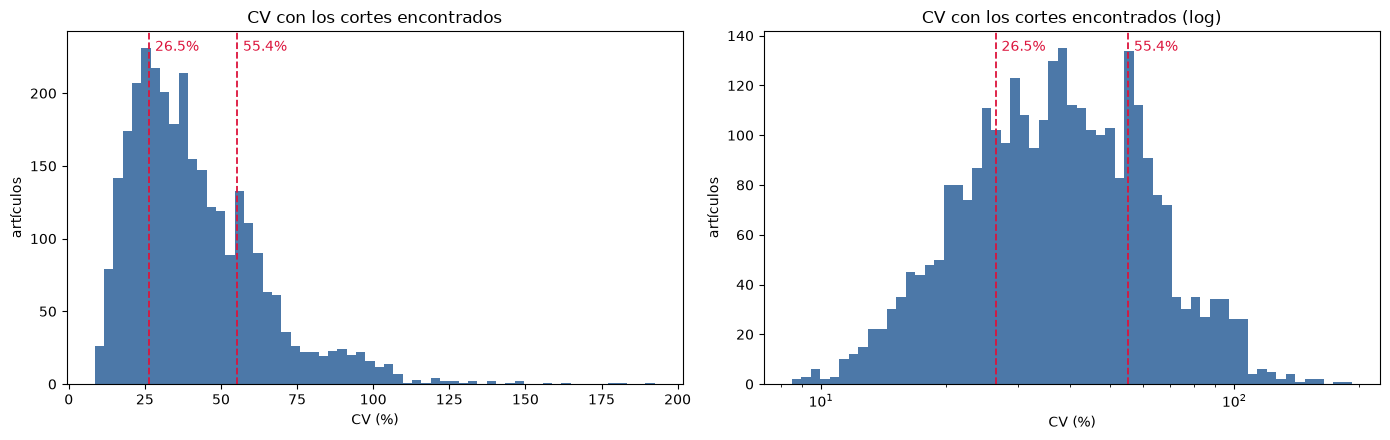

In [21]:
# Verificación: gasto medio descendente y mínimo de artículos por segmento.
segs = cuts["segments"]
print("gasto medio descendente X → Z:", segs["mean_spend"].is_monotonic_decreasing)
print(f"mínimo de artículos por segmento: {segs['share_items'].min():.1%} (exigido: {MIN_SHARE:.0%})")

# Los cortes sobre las distribuciones.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, log in zip(axes, (False, True)):
    bins = np.logspace(np.log10(cv_vals.min()), np.log10(cv_vals.max()), 60) if log else 60
    ax.hist(cv_vals, bins=bins, color="#4c78a8")
    if log:
        ax.set_xscale("log")
    for thr in cuts["thresholds"]:
        ax.axvline(thr, color="crimson", linestyle="--", linewidth=1.3)
        ax.annotate(f"{thr:.1f}%", (thr, 1.0), xycoords=("data", "axes fraction"),
                    xytext=(4, -14), textcoords="offset points", color="crimson")
    ax.set(title="CV con los cortes encontrados" + (" (log)" if log else ""), xlabel="CV (%)", ylabel="artículos")
fig.tight_layout()
plt.show()

### Clases resultantes

Clasificación XYZ con los nuevos cortes (`classify_xyz` aplica con 2 cortes) y cruce con ABC.

In [22]:
new_xyz = classify_xyz(matrix["cv"], cuts["thresholds"]) if N_CUTS == 2 else None
if new_xyz is not None:
    matrix["xyz_class_cv_cuts"] = new_xyz.to_numpy()
    cross = pd.crosstab(matrix["abc_class"].fillna("inactivo"), matrix["xyz_class_cv_cuts"].fillna("-"),
                        margins=True, margins_name="Total")
    assert cross.loc["Total", "Total"] == len(matrix)
    display(cross)
    print("% por fila")
    display((pd.crosstab(matrix["abc_class"].fillna("inactivo"), matrix["xyz_class_cv_cuts"].fillna("-"),
                         normalize="index", margins=True, margins_name="Total") * 100).round(1))
    print("% por columna")
    display((pd.crosstab(matrix["abc_class"].fillna("inactivo"), matrix["xyz_class_cv_cuts"].fillna("-"),
                         normalize="columns", margins=True, margins_name="Total") * 100).round(1))
else:
    print("classify_xyz solo admite 2 cortes; con otro N_CUTS usar los rangos de la tabla de segmentos.")

xyz_class_cv_cuts,X,Y,Z,Total
abc_class,,,,
A,207,297,121,625
B,338,604,245,1187
C,287,614,336,1237
Total,832,1515,702,3049


% por fila


xyz_class_cv_cuts,X,Y,Z
abc_class,,,
A,33.10,47.50,19.40
B,28.50,50.90,20.60
C,23.20,49.60,27.20
Total,27.30,49.70,23.00


% por columna


xyz_class_cv_cuts,X,Y,Z,Total
abc_class,,,,
A,24.90,19.60,17.20,20.50
B,40.60,39.90,34.90,38.90
C,34.50,40.50,47.90,40.60


In [23]:
active["cv"]

0      42.49
1      12.95
2      25.72
3      43.64
4      65.06
        ... 
3044   20.22
3045   34.33
3046   46.18
3047   25.02
3048   35.49
Name: cv, Length: 3049, dtype: float64

In [24]:
raise Exception("Detener")

Exception: Detener

In [26]:
# XYZ: sobre el CV de los artículos activos.

xyz = classify_xyz(active["cv"], cuts["thresholds"])
# display(xyz.value_counts(dropna=False).rename("items").to_frame())

matrix = (
    metrics[["item_id", "active", "usage_units", "spend", "cv", "n_blocks"]]
    .merge(abc[["item_id", "cum_spend", "cum_pct_before", "abc_class"]], on="item_id", how="left")
    .merge(
        pd.DataFrame({"item_id": active["item_id"].to_numpy(), "xyz_class": xyz.to_numpy()}),
        on="item_id",
        how="left",
    )
    .sort_values(["active", "spend", "item_id"], ascending=[False, False, True])
    .reset_index(drop=True)
)

display(
    xyz.value_counts(dropna=False).rename("items").to_frame().style.set_caption("Clases XYZ"),
    matrix.head(10).style.set_caption("Matriz")
    )

,items
Y,1515
X,832
Z,702


,item_id,active,usage_units,spend,cv,n_blocks,cum_spend,cum_pct_before,abc_class,xyz_class
0,FOODS_3_120,True,290132.000000,1444850.105271,38.649821,56,1444850.105271,0.000000,A,Y
1,FOODS_3_586,True,873745.000000,1395728.806002,13.502093,65,2840578.911273,0.007875,A,X
2,FOODS_3_090,True,1008855.000000,1366337.795356,50.896951,65,4206916.706629,0.015483,A,Y
3,FOODS_3_202,True,286712.000000,1212799.692382,25.378006,65,5419716.399011,0.022930,A,X
4,FOODS_3_587,True,363263.000000,893838.151803,44.959768,65,6313554.550814,0.029540,A,Y
5,FOODS_3_252,True,540928.000000,823269.655651,18.203203,65,7136824.206465,0.034412,A,X
6,FOODS_3_555,True,462462.000000,736589.364402,19.014476,65,7873413.570867,0.038899,A,X
7,FOODS_3_444,True,109137.000000,719129.244241,103.242640,55,8592542.815108,0.042914,A,Z
8,HOBBIES_1_354,True,31143.000000,711937.128559,76.849040,31,9304479.943667,0.046833,A,Z
9,FOODS_1_096,True,92901.000000,645559.484986,74.986512,65,9950039.428653,0.050714,A,Z


In [27]:
# Matriz final: métricas + clase ABC + clase XYZ por artículo (inactivos al final, sin clase).

matrix["cell"] = np.where(matrix["active"], matrix["abc_class"].fillna("") + matrix["xyz_class"].fillna("-"), None)
display(matrix.head(10))
display(matrix.tail(5))

# Control: el mismo resultado debe salir de build_matrix (la función que usa el pipeline).
ref = build_matrix("check", source_data_artifact, start_d, end_d, seg, source_data_artifact["week_of_day"]).set_index("item_id")
mine = matrix.set_index("item_id").loc[ref.index]
same_abc = (mine["abc_class"].fillna("-") == ref["abc_class"].fillna("-")).all()
same_xyz = (mine["xyz_class"].fillna("-") == ref["xyz_class"].fillna("-")).all()
print("coincide con build_matrix · ABC:", same_abc, "· XYZ:", same_xyz)

,item_id,active,usage_units,spend,cv,n_blocks,cum_spend,cum_pct_before,abc_class,xyz_class,cell
0,FOODS_3_120,True,"290,132.00","1,444,850.11",38.65,56,"1,444,850.11",0.00,A,Y,AY
1,FOODS_3_586,True,"873,745.00","1,395,728.81",13.50,65,"2,840,578.91",0.01,A,X,AX
2,FOODS_3_090,True,"1,008,855.00","1,366,337.80",50.90,65,"4,206,916.71",0.02,A,Y,AY
3,FOODS_3_202,True,"286,712.00","1,212,799.69",25.38,65,"5,419,716.40",0.02,A,X,AX
4,FOODS_3_587,True,"363,263.00","893,838.15",44.96,65,"6,313,554.55",0.03,A,Y,AY
5,FOODS_3_252,True,"540,928.00","823,269.66",18.20,65,"7,136,824.21",0.03,A,X,AX
6,FOODS_3_555,True,"462,462.00","736,589.36",19.01,65,"7,873,413.57",0.04,A,X,AX
7,FOODS_3_444,True,"109,137.00","719,129.24",103.24,55,"8,592,542.82",0.04,A,Z,AZ
8,HOBBIES_1_354,True,"31,143.00","711,937.13",76.85,31,"9,304,479.94",0.05,A,Z,AZ
9,FOODS_1_096,True,"92,901.00","645,559.48",74.99,65,"9,950,039.43",0.05,A,Z,AZ


,item_id,active,usage_units,spend,cv,n_blocks,cum_spend,cum_pct_before,abc_class,xyz_class,cell
3044,HOBBIES_2_023,True,845.00,819.65,31.55,21,"183,468,058.29",1.00,C,Y,CY
3045,HOBBIES_2_065,True,"1,342.00",671.00,42.64,27,"183,468,729.29",1.00,C,Y,CY
3046,HOBBIES_2_047,True,"1,063.00",550.96,57.73,40,"183,469,280.25",1.00,C,Z,CZ
3047,HOBBIES_2_025,True,927.00,463.50,21.14,27,"183,469,743.75",1.00,C,X,CX
3048,HOBBIES_2_026,True,"1,991.00",457.93,65.18,27,"183,470,201.68",1.00,C,Z,CZ


coincide con build_matrix · ABC: False · XYZ: False


## 4 · Matriz cruzada ABC × XYZ

Recuento de artículos. `-` en XYZ = CV indefinido; `inactivo` en ABC = sin ventas en la ventana.

In [28]:
abc_lbl = matrix["abc_class"].fillna("inactivo")
xyz_lbl = matrix["xyz_class"].fillna("-")

counts = pd.crosstab(abc_lbl, xyz_lbl, margins=True, margins_name="Total")
assert counts.loc["Total", "Total"] == len(matrix), "la tabla debe sumar todos los artículos"
print(f"total de artículos en la tabla: {counts.loc['Total', 'Total']}")
display(counts)

total de artículos en la tabla: 3049


xyz_class,X,Y,Z,Total
abc_class,,,,
A,207,297,121,625
B,338,604,245,1187
C,287,614,336,1237
Total,832,1515,702,3049


In [29]:
# % sobre el total de cada fila (cómo se reparte cada clase ABC entre X, Y y Z).
by_row = pd.crosstab(abc_lbl, xyz_lbl, normalize="index", margins=True, margins_name="Total") * 100
print("% por fila")
display(by_row.round(2))

# % sobre el total de cada columna (cómo se reparte cada clase XYZ entre A, B y C).
by_col = pd.crosstab(abc_lbl, xyz_lbl, normalize="columns", margins=True, margins_name="Total") * 100
print("% por columna")
display(by_col.round(2))

% por fila


xyz_class,X,Y,Z
abc_class,,,
A,33.12,47.52,19.36
B,28.48,50.88,20.64
C,23.20,49.64,27.16
Total,27.29,49.69,23.02


% por columna


xyz_class,X,Y,Z,Total
abc_class,,,,
A,24.88,19.60,17.24,20.50
B,40.62,39.87,34.90,38.93
C,34.50,40.53,47.86,40.57
